In [0]:
import json
import os
from urllib.parse import urljoin
import pandas as pd
import requests

BASE_URL = "https://cvijan.github.io/nss-api/v2/"
FILES_URL = "https://cvijan.github.io/nss-api/files/"
RAW_DIR = "data/raw"
PROCESSED_DIR = "data/processed"

In [0]:
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

In [0]:
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

In [0]:
def get_json(url: str) -> dict:
    r = requests.get(url)
    r.raise_for_status()

    return r.json()

In [0]:
def fetch_all(first_url: str) -> list:
    url = first_url
    content = []

    while url:
        response = get_json(url)
        content.extend(response["data"])
        url = urljoin(first_url, response["next"]) if response["next"] else None

    return content

In [0]:
def save_json(records: list, path: str) -> None:
    with open(path, "w") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)

In [0]:
def download_file(url: str, path: str) -> int:
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(path, "wb") as f:
        f.write(response.content)

    return len(response.content)

In [0]:
def extract(raw_dir: str) -> dict:
    orders = fetch_all(BASE_URL + "orders/page-1.json")
    save_json(orders, os.path.join(RAW_DIR, "orders.json"))

    download_file(FILES_URL + "products.csv", os.path.join(raw_dir, "products.csv"))
    download_file(FILES_URL + "teams.csv", os.path.join(raw_dir, "teams.csv"))
    download_file(
        FILES_URL + "matches.parquet", os.path.join(raw_dir, "matches.parquet")
    )

    df_orders = pd.json_normalize(orders, sep="_").rename(
        columns={"customer_name": "customer", "customer_city": "city"}
    )
    df_products = pd.read_csv(os.path.join(raw_dir, "products.csv"))
    df_teams = pd.read_csv(os.path.join(raw_dir, "teams.csv"))
    df_matches = pd.read_parquet(os.path.join(raw_dir, "matches.parquet"))

    return {
        "orders": df_orders,
        "products": df_products,
        "teams": df_teams,
        "matches": df_matches,
    }

In [0]:
def clean_products(df: pd.DataFrame) -> pd.DataFrame:
    df_products = df.copy()
    df_products = df_products.drop_duplicates("product_id", keep="first")

    df_products["team_code"] = df_products["team_code"].str.strip().str.upper()
    df_products["category"] = df_products["category"].str.strip().str.lower()
    df_products["price"] = df_products["price"].str.replace(" RSD", "", regex=False)
    df_products["price"] = pd.to_numeric(df_products["price"], errors="coerce")
    df_products["active"] = np.where(
        df_products["active"].str.upper() == "YES", True, False
    )

    return df_products

In [0]:
def clean_orders(df: pd.DataFrame) -> pd.DataFrame:
    df_orders = df.copy()
    for col in ["order_id", "customer", "city", "payment"]:
        df_orders[col] = df_orders[col].str.strip()
    df_orders["order_id"] = df_orders["order_id"].str.upper()
    df_orders["customer"] = df_orders["customer"].str.title()
    df_orders["city"] = df_orders["city"].str.title().fillna("Unknown")

    return df_orders

In [0]:
def remove_duplicate_orders(df: pd.DataFrame) -> tuple:
    duplicates_mask = df.duplicated("order_id", keep="first")

    return df[~duplicates_mask], df[duplicates_mask]

In [0]:
def validate_order(row: dict, product_ids: set) -> str:
    quantity = pd.to_numeric(row["quantity"], errors="coerce")
    price = pd.to_numeric(row["unit_price"], errors="coerce")

    if not row["order_id"].startswith("NSS-"):
        return "invalid_order"
    if pd.isna(row["quantity"]):
        return "missing_quantity"
    if pd.isna(quantity) or quantity != int(quantity) or quantity <= 0:
        return "invalid_quantity"
    if pd.isna(price) or price <= 0:
        return "invalid_price"
    if row["product_id"] not in product_ids:
        return "unknown_product"

    return "OK"

In [0]:
def transform_orders(df: pd.DataFrame, products: pd.DataFrame) -> pd.DataFrame:
    df_orders = df.copy()
    df_orders["quantity"] = pd.to_numeric(
        df_orders["quantity"], errors="coerce"
    ).astype(int)
    df_orders["unit_price"] = pd.to_numeric(
        df_orders["unit_price"], errors="coerce"
    ).astype(float)
    df_orders["order_date"] = pd.to_datetime(df_orders["order_date"], errors="coerce")
    df_orders["total"] = df_orders["quantity"] * df_orders["unit_price"]

    prod_columns = products[["product_name", "team_code", "category", "product_id"]]

    return df_orders.merge(prod_columns, on="product_id", how="left")

In [0]:
def split_orders(df: pd.DataFrame, products: pd.DataFrame) -> tuple:
    df_raw = df.copy()
    df_cleaned_orders = clean_orders(df_raw)
    unique, duplicates = remove_duplicate_orders(df_cleaned_orders)
    duplicates = duplicates.assign(reason="duplicate")

    product_ids = set(products["product_id"])
    reasons = unique.apply(lambda row: validate_order(row, product_ids), axis=1)

    valid = transform_orders(unique[reasons == "OK"], products)
    rejected = pd.concat(
        [unique[reasons != "OK"].assign(reason=reasons[reasons != "OK"]), duplicates]
    )

    return valid, rejected

In [0]:
def team_results(matches: pd.DataFrame, teams: pd.DataFrame) -> pd.DataFrame:
    df_matches = matches.copy()
    played = df_matches.query('status == "finished"')

    codes = dict(zip(teams["team_id"], teams["code"]))
    home = pd.DataFrame(
        {
            "match_id": played["match_id"],
            "match_date": played["kickoff_ts"].dt.normalize(),
            "team_code": played["home_team_id"].map(codes),
            "opponent_code": played["away_team_id"].map(codes),
            "goals_for": played["home_goals"],
            "goals_against": played["away_goals"],
        }
    )

    away = pd.DataFrame(
        {
            "match_id": played["match_id"],
            "match_date": played["kickoff_ts"].dt.normalize(),
            "team_code": played["away_team_id"].map(codes),
            "opponent_code": played["home_team_id"].map(codes),
            "goals_for": played["away_goals"],
            "goals_against": played["home_goals"],
        }
    )

    both_sides_matches = pd.concat([home, away], ignore_index=True).sort_values(
        ["match_id", "match_date"]
    )

    both_sides_matches["result"] = "D"
    both_sides_matches.loc[
        both_sides_matches["goals_for"] > both_sides_matches["goals_against"], "result"
    ] = "W"
    both_sides_matches.loc[
        both_sides_matches["goals_for"] < both_sides_matches["goals_against"], "result"
    ] = "L"
    scores = {"W": 3, "D": 1, "L": 0}
    both_sides_matches["points"] = both_sides_matches["result"].map(scores)

    return both_sides_matches

In [0]:
def league_table(results: pd.DataFrame) -> pd.DataFrame:
    df_table = results.copy()
    df_table = df_table.groupby("team_code").agg(
        played=("match_id", "count"),
        won=("result", lambda res: (res == "W").sum()),
        drawn=("result", lambda res: (res == "D").sum()),
        lost=("result", lambda res: (res == "L").sum()),
        goals_for=("goals_for", "sum"),
        goals_against=("goals_against", "sum"),
        points=("points", "sum"),
    )

    df_table["goal_diff"] = df_table["goals_for"] - df_table["goals_against"]
    df_table = df_table.sort_values(
        ["points", "goal_diff", "goals_for"], ascending=[False, False, False]
    ).reset_index()
    df_table["position"] = df_table.index + 1
    df_table = df_table[
        [
            "position",
            "team_code",
            "played",
            "won",
            "drawn",
            "lost",
            "goals_for",
            "goals_against",
            "goal_diff",
            "points",
        ]
    ]

    return df_table

In [0]:
def match_windows(results: pd.DataFrame) -> pd.DataFrame:
    df_window = results.copy()
    df_window = df_window[["team_code", "match_date", "result"]].rename(
        columns={"match_date": "date", "result": "window"}
    )
    windows = []

    for d in range(4):
        window_copy = df_window.copy()
        window_copy["date"] = window_copy["date"] + pd.Timedelta(days=d)
        windows.append(window_copy)

    df_windows = pd.concat(windows, ignore_index=True)

    return df_windows

In [0]:
def revenue_by(df: pd.DataFrame, column: str) -> pd.DataFrame:
    return (
        df.groupby(column)["total"]
        .sum()
        .reset_index(name="revenue")
        .sort_values("revenue", ascending=False)
    )

In [0]:
def sales_after_results(valid: pd.DataFrame, windows: pd.DataFrame) -> pd.DataFrame:
    teams = pd.DataFrame({"team_code": windows["team_code"].unique()})
    days = pd.DataFrame({"order_date": valid["order_date"].unique()})
    calendar = teams.merge(days, how="cross")

    revenue_by_team_date = (
        valid.groupby(["team_code", "order_date"])["total"]
        .sum()
        .reset_index(name="revenue")
    )
    revenue_by_team_all_dates = calendar.merge(
        revenue_by_team_date, on=["team_code", "order_date"], how="left"
    ).fillna(0)

    calendar_window = revenue_by_team_all_dates.merge(
        windows,
        left_on=["team_code", "order_date"],
        right_on=["team_code", "date"],
        how="left",
    ).fillna("break")

    revenue_by_window = (
        calendar_window.groupby("window", as_index=False)
        .agg(
            team_days=("order_date", "size"),
            revenue=("revenue", "sum"),
            avg_daily_revenue=("revenue", "mean"),
        )
        .round(2)
        .sort_values("avg_daily_revenue", ascending=False)
    )

    return revenue_by_window

In [0]:
def plot_sales_after_results(effect: pd.DataFrame, path: str) -> None:
    fig, ax = plt.subplots()
    ax.bar(effect["window"], effect["avg_daily_revenue"])
    ax.set_ylabel("Revenue")
    ax.set_xlabel("Window")
    ax.set_title("Team win has had a big impact on team's products sales")
    fig.savefig(os.path.join(path, "sales_after_results.png"))
    plt.show()

In [0]:
def top_customers(df: pd.DataFrame, n: int) -> list:
    best_customers = (
        df.groupby("customer", as_index=False)["total"]
        .sum()
        .sort_values("total", ascending=False)
        .head(n)
    )

    return list(best_customers.itertuples(index=False, name=None))

In [0]:
def load(outputs: dict, processed_dir: str) -> dict:
    written = {}
    for name, df in outputs.items():
        path = os.path.join(processed_dir, name)
        if name.endswith(".parquet"):
            df.to_parquet(path, index=False)
        else:
            df.to_csv(path, index=False)
        written[name] = len(df)

    return written

In [0]:
def log(message: str, path: str) -> None:
    time_now = datetime.now()
    formatted_time = time_now.strftime("%Y-%m-%d %H:%M:%S")
    with open(os.path.join(path, "pipeline.log"), "a") as f:
        f.write(f"{formatted_time} | {message}\n")

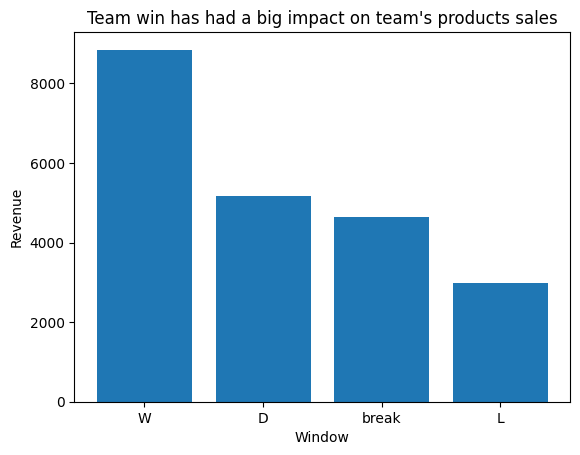

{'total_rows': 1852,
 'duplicates': 12,
 'valid_rows': 1800,
 'rejected_rows': 52,
 'total_revenue': 10045400.0,
 'files_written': 8}

In [0]:
def run_pipeline(raw_dir: str, processed_dir: str) -> dict:
    log("Pipeline started", processed_dir)

    data = extract(raw_dir)
    log("Data extraction completed", processed_dir)

    products = clean_products(data["products"])
    log("Products cleaned", processed_dir)

    valid, rejected = split_orders(data["orders"], products)
    log("Orders cleaned, deduplicated, validated and transformed", processed_dir)

    results = team_results(data["matches"], data["teams"])
    log("Team results prepared", processed_dir)
    windows = match_windows(results)
    log("Match windows created", processed_dir)

    sales_results = sales_after_results(valid, windows)
    log("Sales analysis completed", processed_dir)
    plot_sales_after_results(sales_results, processed_dir)
    log("Revenue bar chart created and saved", processed_dir)

    outputs = {
        "clean_orders.parquet": valid,
        "rejected_orders.csv": rejected,
        "products.csv": products,
        "league_table.csv": league_table(results),
        "revenue_by_team.csv": revenue_by(
            valid.dropna(subset=["team_code"]), "team_code"
        ),
        "revenue_by_category.csv": revenue_by(valid, "category"),
        "sales_after_results.csv": sales_results,
    }

    written = load(outputs, processed_dir)
    log(f"{len(written)} output files written", processed_dir)

    summary = {
        "total_rows": len(data["orders"]),
        "duplicates": int((rejected["reason"] == "duplicate").sum()),
        "valid_rows": len(valid),
        "rejected_rows": len(rejected),
        "total_revenue": round(float(valid["total"].sum()), 2),
        "files_written": len(written) + 1,
    }

    pd.DataFrame(list(summary.items()), columns=["metric", "value"]).to_csv(
        os.path.join(processed_dir, "summary.csv"), index=False
    )
    log("Summary file saved", processed_dir)
    log("Pipeline completed successfully", processed_dir)

    return summary


run_pipeline(RAW_DIR, PROCESSED_DIR)